In [1]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from scipy.special import jv
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import mpmath
from mpmath import *
import time
import pandas as pd
import matplotlib
import matplotlib.image
import matplotlib.lines as mlines
import matplotlib.patches as mpatches




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF  import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF  import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Get Treated Data

In [ ]:
path = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet'

Simu_Data = {}
Simu_SPR_data = {}
Exp_Data = {}
Plot_dic = {}
Points = {}


path_simu = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\SPR'

Sample_name_list = ['Sapphire', 'Silice thick', 'Silice membrane', 'Silice thick - e 30 nm']
Sample_name_list = ['Sapphire', 'Silice thick', 'Silice membrane']

Geometry_choice = 'cylinder'

h = 23



Colors_list = ["#377eb8", '#984ea3', "#4daf4a", "#e41a1c", "#ff7f00"]

Markers_list = ["o", 'H', 'v', '*', 'X']


for k in range(len(Sample_name_list)) :
    sample_name = Sample_name_list[k]
    color = Colors_list[k]
    marker = Markers_list[k]
    
    Simu_SPR_data[sample_name] = {}
    print(sample_name)
    
    root_exp = '\\'.join((path, sample_name, r'AR_estimation\ND_measurements_AR_treated'))
    
    Exp_Data[sample_name] = get_treated_AR_data(root_exp, 'Treated_data - ' + Geometry_choice + ' - h ' + str(h) + 'nm')
    


    root_simu = '\\'.join((path_simu, sample_name, Geometry_choice, r'Treated_SPR'))
    res = get_SPR_simu_data_and_interpolate(root_simu, 'Treated_simulations', kernel='linear')
    Simu_SPR_data[sample_name], Simu_SPR_data[sample_name]['Lda_RBF'], Simu_SPR_data[sample_name]['E_RBF'], Simu_SPR_data[sample_name]['W_RBF'], Simu_SPR_data[sample_name]['Aire_RBF'], Points[sample_name] = res

    Plot_dic[sample_name] = {}
    Plot_dic[sample_name]['main'] = color
    Plot_dic[sample_name]['marker'] = marker
    Plot_dic[sample_name]['exp_dir_root'] = path + '\\' + sample_name + r'\Figures'



Sapphire
Silice thick
Silice membrane


## Key in my dictionnaries

ND dictionnary useful keys :

ND['1D']['D', 'h', 'AR']

ND['2D']['D', 'h', 'AR']

  


## Find closets point

In [3]:
h, D = 30, 71
compt = 0
for key in Simu_SPR_data :

    print('-----------------------------------------------')
    print(key)
    
    simu = Simu_SPR_data[key]
    if compt == 0 :
            
        for kkey in simu :
            print(kkey)

            ccompt = 0
        for kkkey in Exp_Data[key] :
            if ccompt==0 :

                print([str(x) for x in Exp_Data[key][kkkey]] )
            ccompt +=1
    #compt +=1

-----------------------------------------------
Sapphire
ND_D_40.0_h_20.0
ND_D_40.0_h_25.0
ND_D_40.0_h_30.0
ND_D_40.0_h_35.0
ND_D_50.0_h_20.0
ND_D_50.0_h_25.0
ND_D_60.0_h_20.0
ND_D_60.0_h_25.0
ND_D_60.0_h_30.0
ND_D_60.0_h_35.0
ND_D_70.0_h_20.0
ND_D_70.0_h_25.0
ND_D_70.0_h_30.0
ND_D_70.0_h_35.0
ND_D_80.0_h_20.0
ND_D_80.0_h_25.0
ND_D_80.0_h_30.0
ND_D_90.0_h_20.0
ND_D_90.0_h_25.0
ND_D_90.0_h_30.0
ND_D_90.0_h_35.0
ND_D_100.0_h_20.0
ND_D_100.0_h_25.0
ND_D_100.0_h_30.0
ND_D_100.0_h_35.0
ND_D_110.0_h_20.0
ND_D_110.0_h_25.0
ND_D_110.0_h_30.0
ND_D_110.0_h_35.0
ND_D_120.0_h_20.0
ND_D_120.0_h_25.0
ND_D_120.0_h_30.0
ND_D_120.0_h_35.0
ND_D_130.0_h_20.0
ND_D_130.0_h_25.0
ND_D_50.0_h_30.0
ND_D_50.0_h_35.0
ND_D_80.0_h_35.0
ND_D_40.0_h_40.0
ND_D_50.0_h_40.0
ND_D_60.0_h_40.0
ND_D_70.0_h_40.0
ND_D_80.0_h_40.0
ND_D_90.0_h_40.0
ND_D_100.0_h_40.0
ND_D_110.0_h_40.0
ND_D_120.0_h_40.0
ND_D_40.0_h_45.0
ND_D_50.0_h_45.0
ND_D_60.0_h_45.0
ND_D_70.0_h_45.0
ND_D_80.0_h_45.0
ND_D_90.0_h_45.0
ND_D_100.0_h_45.0
ND_D_11

## Plot the 2D convergene

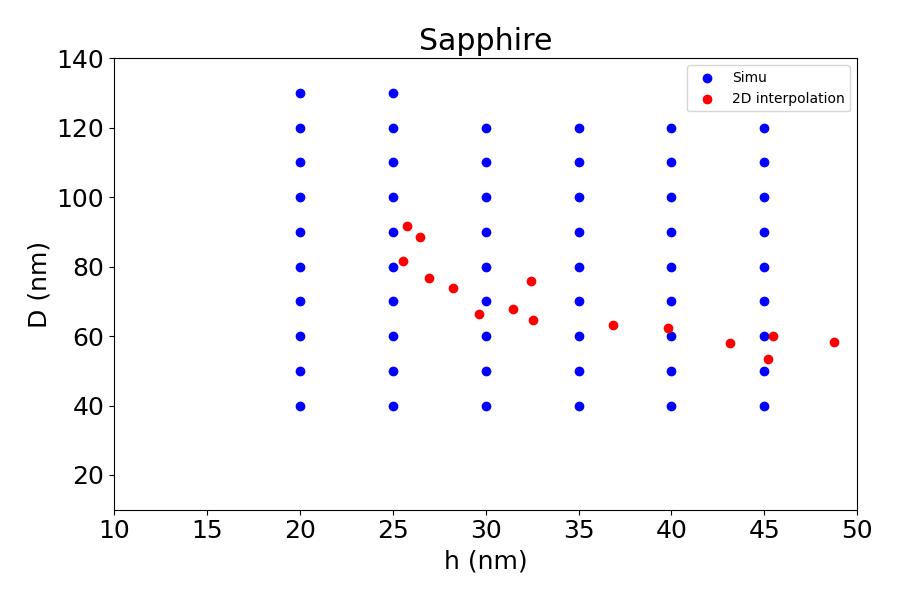

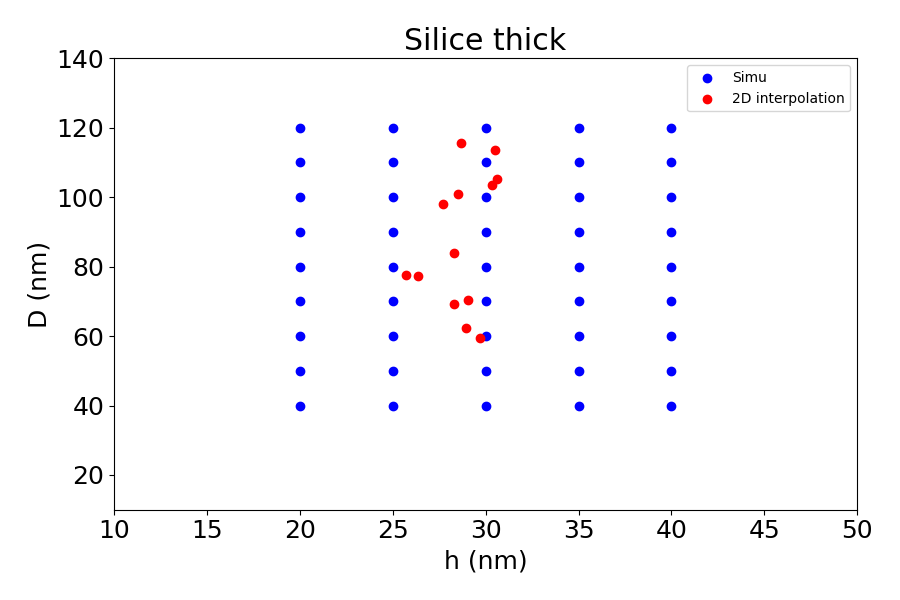

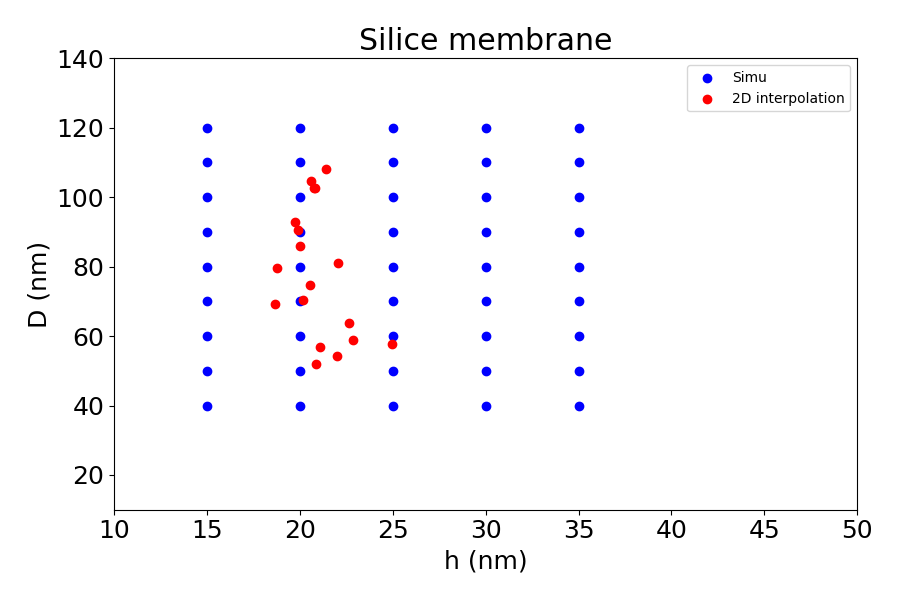

In [4]:
for key in Simu_SPR_data :

    fig, ax = plt.subplots(figsize = (9,6))

    
    simu_data = Simu_SPR_data[key]
    exp_data = Exp_Data[key]
    points = Points[key]
    
    print_2D_AR_interpolations(exp_data, points, ax)

    ax.set_title(key)

    plt.legend(fontsize=10)
    plt.tight_layout()


    dir_to_save = Plot_dic[key]['exp_dir_root'] + r'\AR_estimation'
    if not(os.path.exists(dir_to_save)) :
        os.mkdir(dir_to_save)
    os.chdir(dir_to_save)
    plt.savefig('2D AR interpolation - ' + Geometry_choice + '.pdf')
    plt.savefig('2D AR interpolation - ' + Geometry_choice + '.png')

## Plot reduced frequencies

## Show experimental fit of spectra, and the spectra corresponding of fitted AR

In [5]:
show_closest_fit = 0
show_exact_fit = 1

tested_sample = 'Sapphire'

In [6]:
if show_closest_fit :

    simu = Simu_SPR_data[tested_sample]
    exp_data = Exp_Data[tested_sample]
    points = Points[tested_sample]

    E = np.linspace(1.5, 3, 1000)

    for key in exp_data :
        
        ND = exp_data[key]

        

        fig, ax = plt.subplots(figsize=(9,4))
        plt.title(key)
        ax.plot(E, Lorentz_no_offset(E, ND['E_SPR'], ND['w_SPR']*1e-3, ND['Aire_SPR']), color='black', label = 'exp spectra')

        # Get the closest simulated spectra for the extracted geometry.

        # idx_2D = np.argmin(np.linalg.norm(np.array(simu['points']-[ND['h_estimated 2D'], ND['D_estimated 2D']]), axis=1))
        # ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_2D], simu['W'][idx_2D], simu['Aire_SPR'][idx_2D]), color='blue', label = '2D : h = {:.1f}, D = {:.1f}'.format(simu['points'][idx_2D][0],simu['points'][idx_2D][1] ))
        
        # idx_1D_21nm = np.argmin(np.linalg.norm(np.array(simu['points']-[21, ND['D_est_1D']]), axis=1))
        # ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_1D_21nm], simu['W'][idx_1D_21nm], simu['Aire_SPR'][idx_1D_21nm]), color='red', label = '2D : h = 21 nm, D = {:.1f}'.format(simu['points'][idx_1D_21nm][1]))
        
        # idx_1D_25nm = np.argmin(np.linalg.norm(np.array(simu['points']-[25, ND['D_est_1D']]), axis=1))
        # ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_1D_25nm], simu['W'][idx_1D_25nm], simu['Aire_SPR'][idx_1D_25nm]), color='orange', label = '2D : h = 25 nm, D = {:.1f}'.format(simu['points'][idx_1D_25nm][1]))   
        


        # Prend la largeur expérimentale de la résonance, et le spectre simulé le plus proche (seulement à partir des spectres simulés)
        idx_2D = np.argmin(np.linalg.norm(np.array(points-[ND['2D']['h'], ND['2D']['D']]), axis=1))
        ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_2D], ND['w_SPR']*1e-3, simu['Aire_SPR'][idx_2D]), color='blue', label = '2D : h = {:.1f} nm, D = {:.1f} nm / plot ({}, {})'.format(ND['2D']['h'], ND['2D']['D'], simu['points'][idx_2D][0],simu['points'][idx_2D][1] ))
        
        idx_1D_21nm = np.argmin(np.linalg.norm(np.array(points-[21, ND['1D']['D']]), axis=1))
        ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_1D_21nm], ND['w_SPR']*1e-3, simu['Aire_SPR'][idx_1D_21nm]), color='red', label = '1D : h = 21 nm, D = {:.1f} nm / plot({}, {})'.format(ND['1D']['D'], simu['points'][idx_1D_21nm][0], simu['points'][idx_1D_21nm][1]))
        
        idx_1D_25nm = np.argmin(np.linalg.norm(np.array(points-[25, ND['1D']['D']]), axis=1))
        ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_1D_25nm], ND['w_SPR']*1e-3, simu['Aire_SPR'][idx_1D_25nm]), color='orange', label = '1D : h = 25 nm, D = {:.1f} nm / plot({}, {})'.format(ND['1D']['D'], simu['points'][idx_1D_25nm][0], simu['points'][idx_1D_25nm][1]))   
        

        idx_1D_35nm = np.argmin(np.linalg.norm(np.array(points-[35, ND['1D']['D']]), axis=1))
        ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_1D_35nm], ND['w_SPR']*1e-3, simu['Aire_SPR'][idx_1D_35nm]), color='green', label = '1D : h = 35 nm, D = {:.1f} nm / plot({}, {})'.format(ND['1D']['D'], simu['points'][idx_1D_35nm][0], simu['points'][idx_1D_35nm][1]))   
        
        





        ax.legend(fontsize =10)

        ax.set_ylim(top = Lorentz_no_offset(E, ND['E_SPR'], ND['w_SPR']*1e-3, ND['Aire_SPR']).max()*1.3)
        ax.set_xlim((1.5, 3.3))

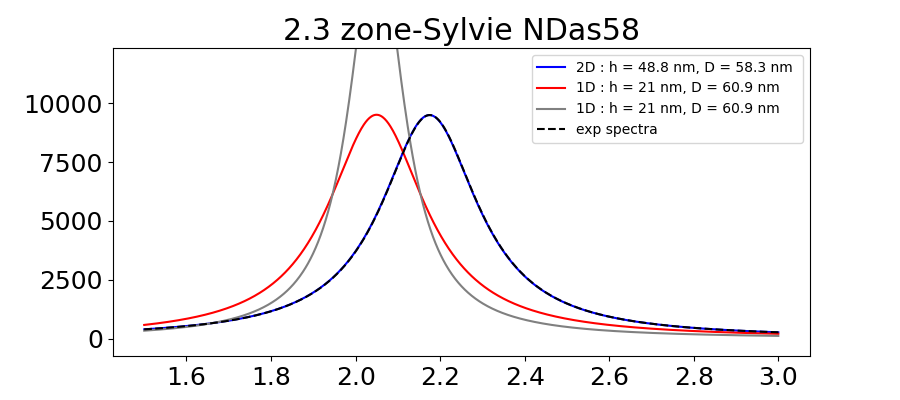

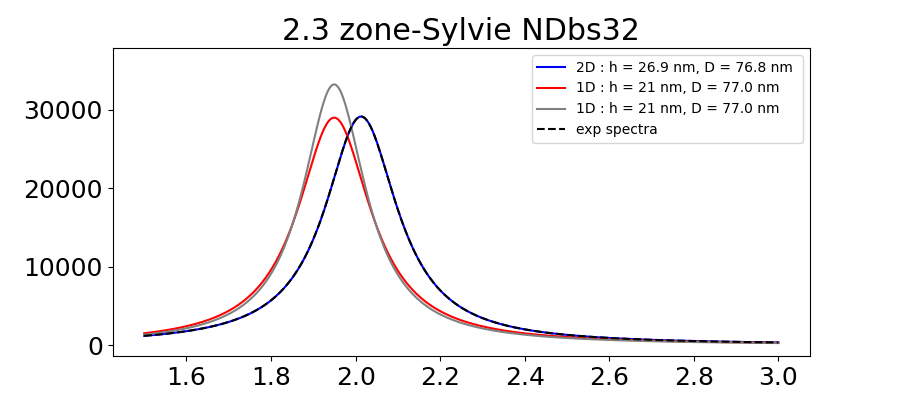

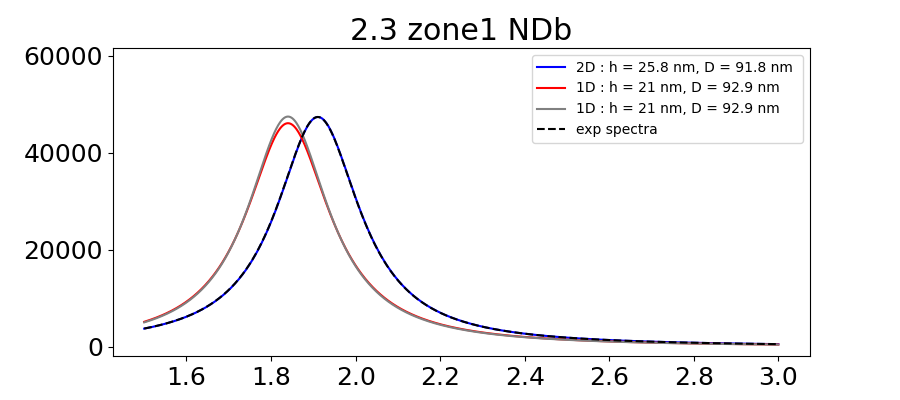

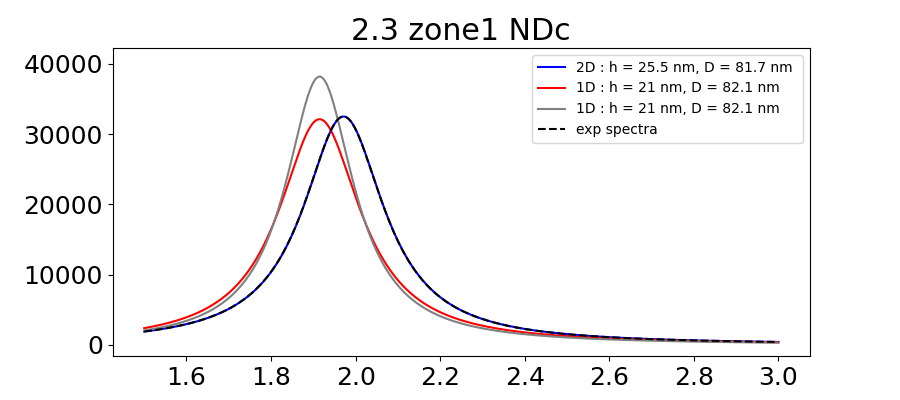

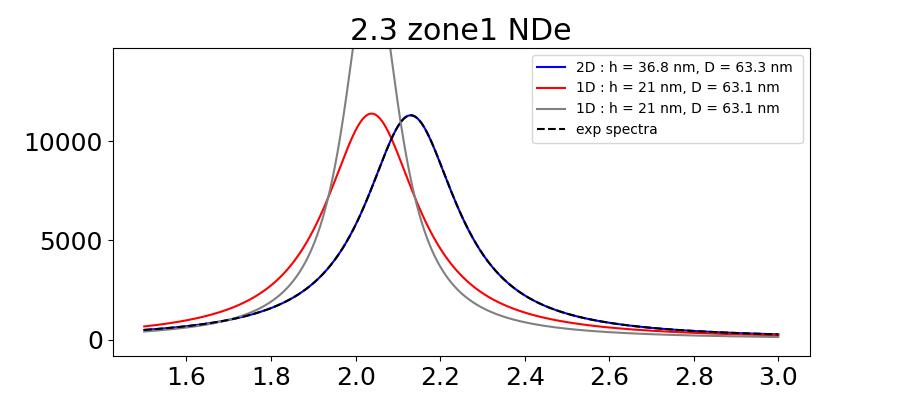

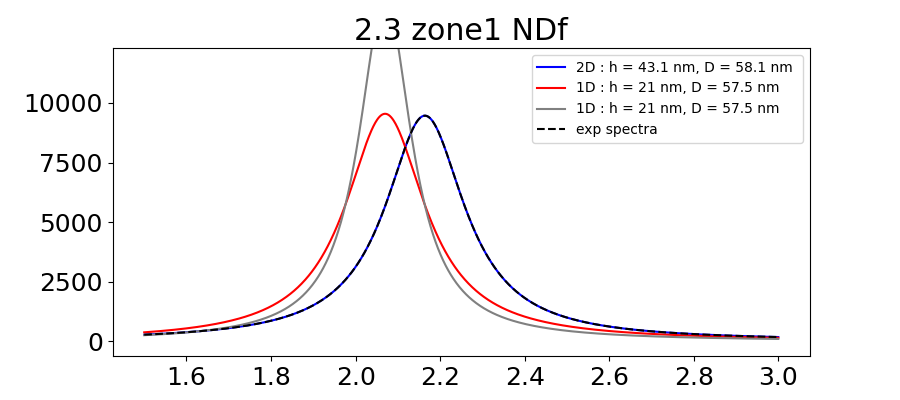

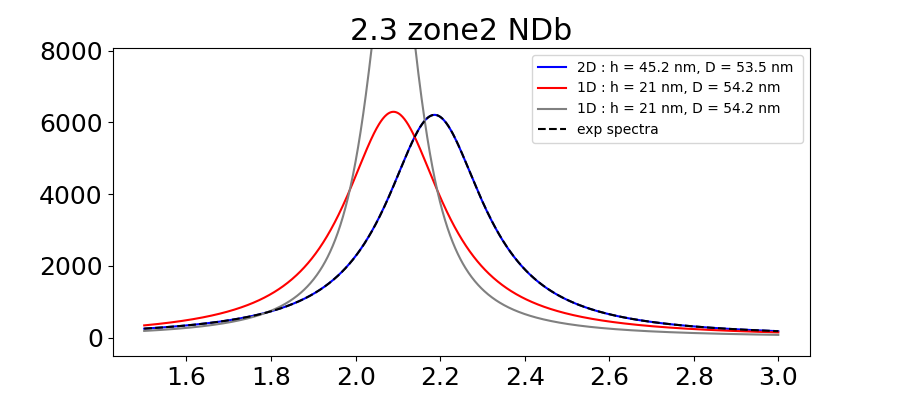

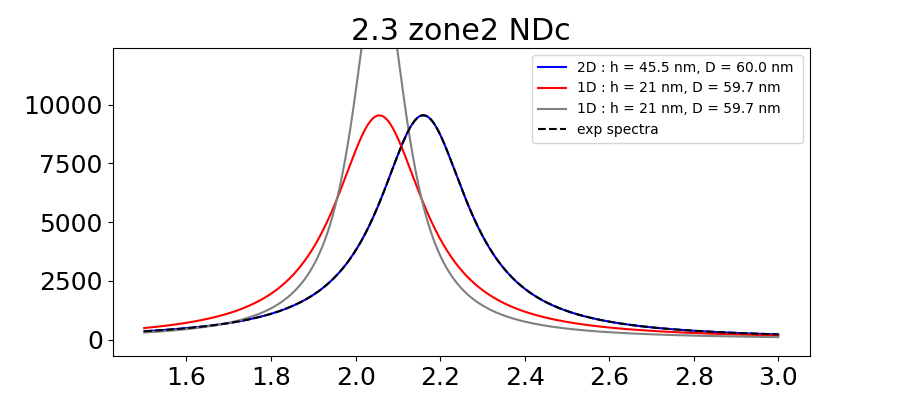

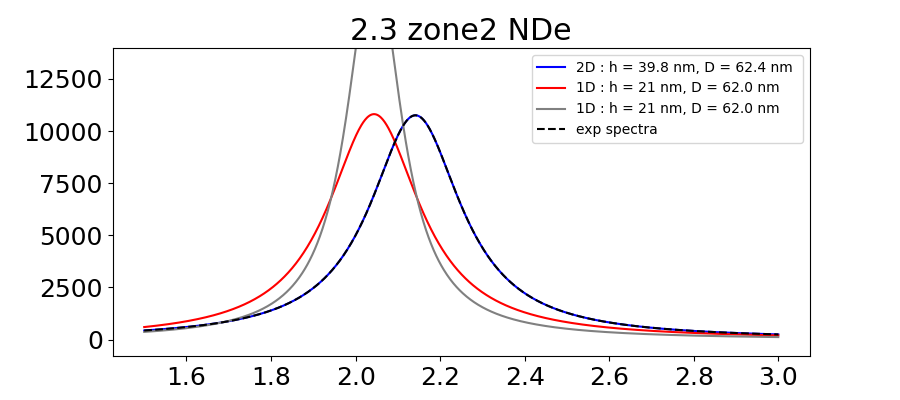

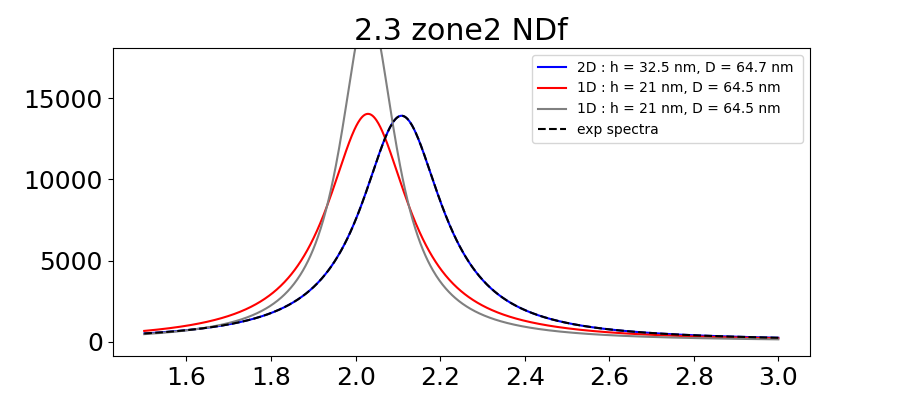

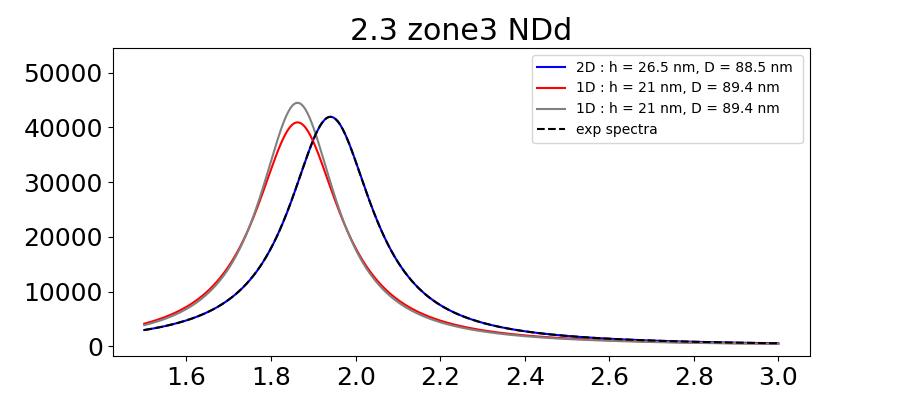

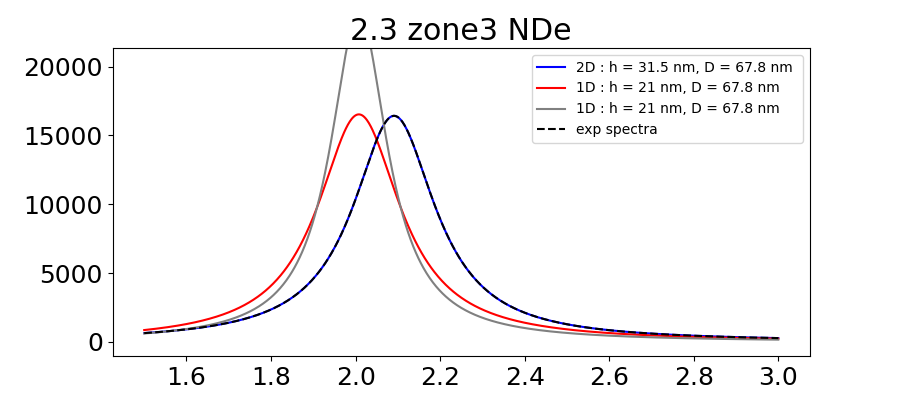

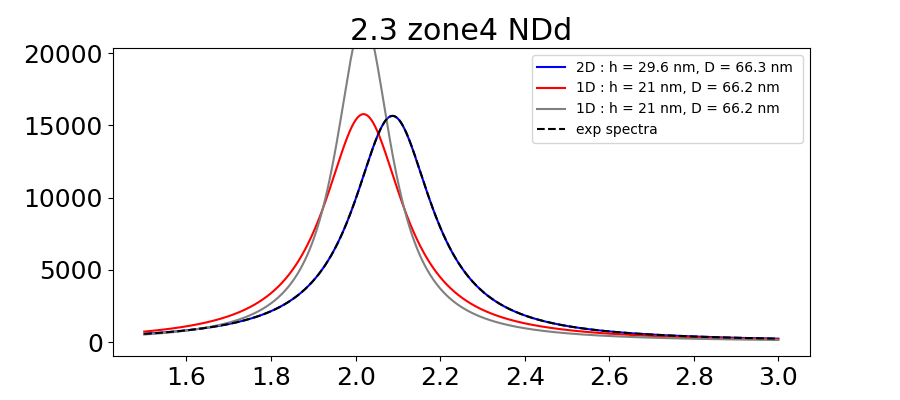

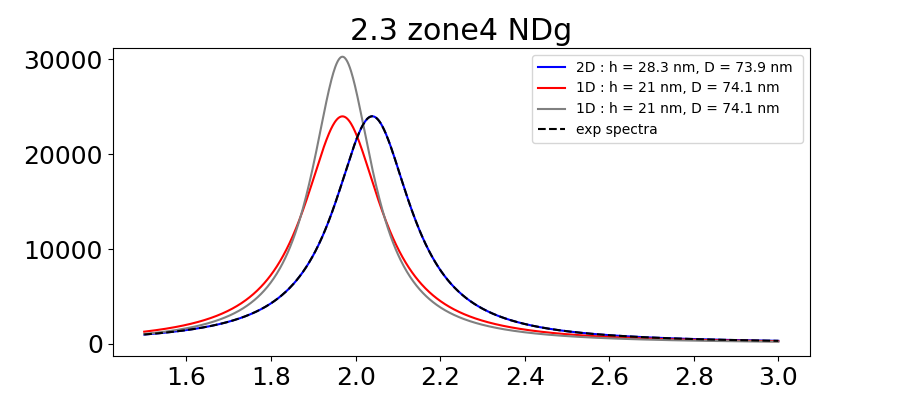

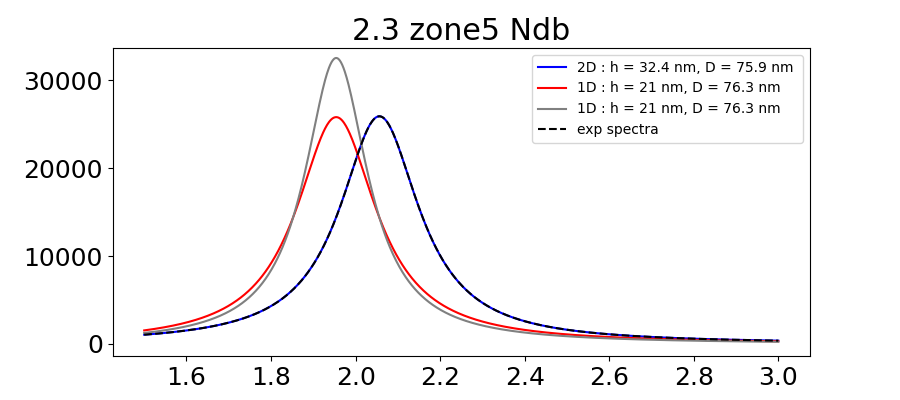

In [7]:
if show_exact_fit :

    simu = Simu_SPR_data[tested_sample]
    exp_data = Exp_Data[tested_sample]
    points = Points[tested_sample]

    E = np.linspace(1.5, 3, 1000)

    for key in exp_data :
        
        ND = exp_data[key]

        

        fig, ax = plt.subplots(figsize=(9,4))
        plt.title(key)
        
        point_2D = [[ND['2D']['h'], ND['2D']['D']]]
        point_1D_21nm = [[21, ND['1D']['D']]]
        point_1D_25nm = [[25, ND['1D']['D']]]
        point_1D_30nm = [[30, ND['1D']['D']]]
        
        ax.plot(E, Lorentz_no_offset(E, simu['E_RBF'](point_2D), ND['w_SPR']*1e-3, simu['Aire_RBF'](point_2D)), color='blue', label = '2D : h = {:.1f} nm, D = {:.1f} nm '.format(ND['2D']['h'], ND['2D']['D'], ))
        

        ax.plot(E, Lorentz_no_offset(E, simu['E_RBF'](point_1D_21nm), ND['w_SPR']*1e-3, simu['Aire_RBF'](point_1D_21nm)), color='red', label = '1D : h = 21 nm, D = {:.1f} nm'.format(ND['1D']['D'] ))
        # ax.plot(E, Lorentz_no_offset(E, simu['E_RBF'](point_1D_25nm), ND['w_SPR']*1e-3, simu['Aire_RBF'](point_1D_25nm)), color='orange', label = '1D : h = 25 nm, D = {:.1f} nm'.format(ND['1D']['D'] ))
        # ax.plot(E, Lorentz_no_offset(E, simu['E_RBF'](point_1D_30nm), ND['w_SPR']*1e-3, simu['Aire_RBF'](point_1D_30nm)), color='green', label = '1D : h = 30 nm, D = {:.1f} nm'.format(ND['1D']['D'] ))

        ax.plot(E, Lorentz_no_offset(E, simu['E_RBF'](point_1D_21nm), simu['W_RBF'](point_1D_21nm)*1e-3, simu['Aire_RBF'](point_1D_21nm)), color='grey', label = '1D : h = 21 nm, D = {:.1f} nm'.format(ND['1D']['D'] ))
        
        # ax.plot(E, Lorentz_no_offset(E, simu['E_SPR'][idx_1D_35nm], ND['w_SPR']*1e-3, simu['Aire_SPR'][idx_1D_35nm]), color='green', label = '1D : h = 25 nm, D = {:.1f} nm'.format(ND['D_est_1D']))   
        ax.plot(E, Lorentz_no_offset(E, ND['E_SPR'], ND['w_SPR']*1e-3, ND['Aire_SPR']),linestyle = '--', color='black', label = 'exp spectra')

        





        ax.legend(fontsize =10)

        ax.set_ylim(top = Lorentz_no_offset(E, ND['E_SPR'], ND['w_SPR']*1e-3, ND['Aire_SPR']).max()*1.3)